In [4]:
# ============================================================
# Progression-Free Survival (PFS) logic:
#
# PFS is calculated at the patient + metastatic therapy line level,
# not simply row-by-row.
#
# Reason:
#   One metastatic therapy line can contain multiple concurrent drugs.
#   For example, patient 1472-17 First-line therapy:
#
#       Met_Hormonal_Therapy   start = 4760
#       Met_Targeted_Therapy   start = 4776
#       Met_Targeted_Therapy   start = 4776
#       End/progression day    = 4965
#
#   The correct treatment-line start is the earliest start date:
#
#       min(4760, 4776, 4776) = 4760
#
#   Therefore:
#
#       PFS = EndTrt_Days_From_Primary_Diagnosis
#             - earliest line start date
#
#       PFS = 4965 - 4760 = 205 days
#
# Implementation:
#   For each patient_id + Met_Therapy_Line:
#       Line_Start_Days_From_Primary_Diagnosis =
#           min(Days_From_Primary_Diagnosis)
#
#   Then, for rows where:
#       Treatment_Response == "Progression"
#
#   Calculate:
#       Progression_Free_Survival =
#           EndTrt_Days_From_Primary_Diagnosis
#           - Line_Start_Days_From_Primary_Diagnosis
#
# Negative PFS handling:
#   If calculated PFS is negative, this likely indicates a source-data issue,
#   for example treatment end/progression day earlier than treatment start day.
#   These values are set to NA in the final PFS column and flagged in
#   PFS_QC_Flag for manual review.
#
#
# Blood-draw TFx logic:
#
# TFx is added at the blood-draw sample level by matching Barcode.
#
# Example:
#   Clinical Barcode:    AMU9-NB1
#   Blood_draws Barcode: AMU9-NB1
#
# Matching key:
#   clinical["Barcode"] == blood_draws["Barcode"]
#
# We match by Barcode, not patient_id, because one patient can have multiple
# blood draws:
#
#   NB1, NB2, NB3, NB4, etc.
#
# Therefore, patient_id alone is not specific enough to assign TFx to the
# correct blood draw.
#
# Only rows with NB blood-draw barcodes receive TFx values. Other clinical
# rows such as Met_Diagnosis, Met_Therapy, Progression_onTx, date_of_death,
# and Overall_Survival_days remain blank for TFx.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

clinical_xlsx = (
    BASE_DIR /
    "Clinical_data/AUP_ClinicalData_20260609.xlsx"
)

clinical_sheet = "AUP_ClinicalData_20260609.NO.DA"

blood_draws_xlsx = (
    BASE_DIR /
    "Clinical_data/All_cases_clinical_CNV_extraction_TSVs/"
    "All_cases_clinical_CNV_extraction.xlsx"
)

blood_draws_sheet = "Blood_draws"

out_dir = BASE_DIR / "Survival"
out_dir.mkdir(parents=True, exist_ok=True)

out_csv = out_dir / "AUP_ClinicalData_20260609_NO_DA_with_PFS_and_blood_draw_TFx.csv"

print("Clinical file:")
print(clinical_xlsx)

print("\nBlood-draw TFx file:")
print(blood_draws_xlsx)

print("\nOutput file:")
print(out_csv)


# ============================================================
# 2. Helper functions
# ============================================================

def clean_patient_id(x):
    """
    Clean patient_id so numeric and character IDs match consistently.

    Examples:
      8       -> "8"
      8.0     -> "8"
      "8.0"   -> "8"
      "1472-17" -> "1472-17"
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def clean_barcode(x):
    """
    Clean barcode for exact matching.

    Examples:
      "AMU9-NB1"    -> "AMU9-NB1"
      " amu9-nb1 "  -> "AMU9-NB1"
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    return s.upper()


def find_first_col(df, candidates, label):
    """
    Find the first matching column name from a candidate list.
    """
    for c in candidates:
        if c in df.columns:
            return c

    raise ValueError(
        f"Could not find {label}.\n"
        f"Tried: {candidates}\n\n"
        f"Available columns:\n{df.columns.tolist()}"
    )


def safe_numeric(x):
    """
    Convert to numeric. Invalid values become NaN.
    """
    return pd.to_numeric(x, errors="coerce")


def excel_col_to_index(col_letter):
    """
    Convert Excel column letter to zero-based Python index.

    Examples:
      A  -> 0
      AF -> 31
      AG -> 32
      AH -> 33
    """
    col_letter = col_letter.upper()
    index = 0

    for char in col_letter:
        index = index * 26 + (ord(char) - ord("A") + 1)

    return index - 1


def insert_or_move_column(df, col_name, values, excel_col_letter):
    """
    Insert or move a column to a desired Excel-like position.
    """
    if col_name in df.columns:
        df = df.drop(columns=[col_name])

    target_index = excel_col_to_index(excel_col_letter)
    insert_index = min(target_index, len(df.columns))

    df.insert(insert_index, col_name, values)

    return df

def clean_receptor_status(x):
    """
    Standardize ER / PR / HER2 receptor status.

    Returns:
      "Positive"
      "Negative"
      pd.NA for missing/unclear/equivocal values
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip().lower()

    if s == "" or s in {"na", "nan", "none", "null", "unknown"}:
        return pd.NA

    # Treat equivocal/indeterminate as missing for clean subgroup assignment
    if "equivocal" in s or "indeterminate" in s or "borderline" in s:
        return pd.NA

    # Negative terms first so "non-amplified" is not mistaken as amplified
    if (
        s in {"negative", "neg", "-", "no", "n", "0"}
        or "negative" in s
        or "not amplified" in s
        or "non-amplified" in s
        or "non amplified" in s
    ):
        return "Negative"

    if (
        s in {"positive", "pos", "+", "yes", "y"}
        or "positive" in s
        or "amplified" in s
        or s == "3+"
    ):
        return "Positive"

    return pd.NA


def assign_breast_subtype(er, pr, her2):
    """
    Assign breast cancer subtype using ER, PR, and HER2.

    Definition:
      HR+ = ER positive OR PR positive
      HR- = ER negative AND PR negative

    Subtypes:
      HR+ Her2-
      HR+ Her2+
      HR- Her2-
      HR- Her2+
    """
    er_clean = clean_receptor_status(er)
    pr_clean = clean_receptor_status(pr)
    her2_clean = clean_receptor_status(her2)

    # HER2 must be known
    if pd.isna(her2_clean):
        return pd.NA

    # HR-positive if either ER or PR is positive
    if er_clean == "Positive" or pr_clean == "Positive":
        hr_label = "HR+"

    # HR-negative only when both ER and PR are confirmed negative
    elif er_clean == "Negative" and pr_clean == "Negative":
        hr_label = "HR-"

    # Otherwise unclear, e.g. ER negative but PR missing
    else:
        return pd.NA

    her2_label = "Her2+" if her2_clean == "Positive" else "Her2-"

    return f"{hr_label} {her2_label}"


def insert_after_column(df, col_name, values, after_col):
    """
    Insert or move a column immediately after another column.
    """
    if col_name in df.columns:
        df = df.drop(columns=[col_name])

    if after_col in df.columns:
        insert_index = df.columns.get_loc(after_col) + 1
    else:
        insert_index = len(df.columns)

    df.insert(insert_index, col_name, values)

    return df
# ============================================================
# 3. Read blood-draw TFx data
# ============================================================

blood = pd.read_excel(
    blood_draws_xlsx,
    sheet_name=blood_draws_sheet,
    dtype=str
)

print("\n========== Blood_draws input ==========")
print("Rows:", blood.shape[0])
print("Columns:", blood.shape[1])
print(blood.columns.tolist())

blood_barcode_col = find_first_col(
    blood,
    candidates=[
        "Barcode",
        "barcode",
        "Aurora_barcode",
        "AURORA_barcode",
        "Sample_Barcode",
        "Sample",
        "sample",
        "Sample_ID",
        "sample_id"
    ],
    label="blood-draw barcode column"
)

tfx_col = find_first_col(
    blood,
    candidates=[
        "Tumor_Fraction_percent_from_CNV_annotation",
        "Tumor_Fraction_percent",
        "TFx_percent",
        "Tumor_Fraction",
        "TFx"
    ],
    label="tumor fraction / TFx column"
)

print("\nDetected blood-draw columns:")
print("Barcode column:", blood_barcode_col)
print("TFx column:", tfx_col)

blood["barcode_clean"] = blood[blood_barcode_col].apply(clean_barcode)
blood["TFx_numeric"] = safe_numeric(blood[tfx_col])

# If TFx appears as 0-1 fraction, convert to percent
if blood["TFx_numeric"].dropna().shape[0] > 0:
    if blood["TFx_numeric"].dropna().max() <= 1:
        print("\nTFx appears to be stored as 0-1 fraction. Converting to percent.")
        blood["TFx_numeric"] = blood["TFx_numeric"] * 100

print("\n========== Blood-draw TFx summary ==========")
print("Rows in Blood_draws:", blood.shape[0])
print("Rows with nonmissing barcode:", blood["barcode_clean"].notna().sum())
print("Rows with nonmissing TFx:", blood["TFx_numeric"].notna().sum())
print("Unique barcodes in Blood_draws:", blood["barcode_clean"].nunique())
print(
    "Unique barcodes with nonmissing TFx:",
    blood.loc[blood["TFx_numeric"].notna(), "barcode_clean"].nunique()
)

# One TFx value per barcode.
# If duplicate barcode rows exist, median TFx is used.
blood_tfx_by_barcode = (
    blood.loc[blood["barcode_clean"].notna()]
    .groupby("barcode_clean", dropna=False)
    .agg(
        TFx=("TFx_numeric", "median"),
        n_blood_rows_for_barcode=("TFx_numeric", "size"),
        n_nonmissing_TFx_for_barcode=("TFx_numeric", lambda x: x.notna().sum())
    )
    .reset_index()
)

duplicate_barcodes = blood_tfx_by_barcode[
    blood_tfx_by_barcode["n_blood_rows_for_barcode"] > 1
].copy()

print("\nBlood-draw barcodes with duplicate rows:", duplicate_barcodes.shape[0])

if duplicate_barcodes.shape[0] > 0:
    print("\nPreview duplicate blood-draw barcodes:")
    print(duplicate_barcodes.head(20).to_string(index=False))


# ============================================================
# 4. Read clinical data
# ============================================================

clinical = pd.read_excel(
    clinical_xlsx,
    sheet_name=clinical_sheet,
    dtype=str
)

print("\n========== Clinical input ==========")
print("Rows:", clinical.shape[0])
print("Columns:", clinical.shape[1])
print(clinical.columns.tolist())

patient_col = find_first_col(
    clinical,
    candidates=["patient_id", "Patient_ID", "patientID"],
    label="patient_id column"
)

category_col = find_first_col(
    clinical,
    candidates=["Category"],
    label="Category column"
)

barcode_col = find_first_col(
    clinical,
    candidates=[
        "Barcode",
        "barcode",
        "Aurora_barcode",
        "AURORA_barcode"
    ],
    label="clinical Barcode column"
)

line_col = find_first_col(
    clinical,
    candidates=["Met_Therapy_Line"],
    label="Met_Therapy_Line column"
)

start_col = find_first_col(
    clinical,
    candidates=["Days_From_Primary_Diagnosis"],
    label="Days_From_Primary_Diagnosis column"
)

end_col = find_first_col(
    clinical,
    candidates=["EndTrt_Days_From_Primary_Diagnosis"],
    label="EndTrt_Days_From_Primary_Diagnosis column"
)

response_col = find_first_col(
    clinical,
    candidates=["Treatment_Response"],
    label="Treatment_Response column"
)
er_col = find_first_col(
    clinical,
    candidates=[
        "ER_Status",
        "ER Status",
        "ER",
        "Tumor Marker #1",
        "Tumor Marker #1 (ER)"
    ],
    label="ER status column"
)

pr_col = find_first_col(
    clinical,
    candidates=[
        "PR_Status",
        "PR Status",
        "PR",
        "Tumor Marker #2",
        "Tumor Marker #2 (PR)"
    ],
    label="PR status column"
)

her2_col = find_first_col(
    clinical,
    candidates=[
        "HER2_Status",
        "HER2 Status",
        "Her2_Status",
        "HER2",
        "Her-2/Neu",
        "BREAST: Her-2/Neu-Desc"
    ],
    label="HER2 status column"
)

print("\nDetected receptor-status columns:")
print("ER column:", er_col)
print("PR column:", pr_col)
print("HER2 column:", her2_col)

clinical["patient_id_clean"] = clinical[patient_col].apply(clean_patient_id)
clinical["barcode_clean"] = clinical[barcode_col].apply(clean_barcode)

# ============================================================
# Assign breast cancer subtype from ER / PR / HER2
# ============================================================

subtype_col = "Subtype"

clinical[subtype_col] = clinical.apply(
    lambda row: assign_breast_subtype(
        row[er_col],
        row[pr_col],
        row[her2_col]
    ),
    axis=1
)

print("\n========== Subtype assignment summary ==========")
print(
    clinical[subtype_col]
    .value_counts(dropna=False)
    .rename_axis("Subtype")
    .reset_index(name="n")
    .to_string(index=False)
)
# ============================================================
# 5. Calculate Progression-Free Survival
# ============================================================

pfs_col = "Progression_Free_Survival"
pfs_flag_col = "PFS_QC_Flag"
line_start_col = "Line_Start_Days_From_Primary_Diagnosis"

clinical[line_col] = (
    clinical[line_col]
    .astype(str)
    .str.strip()
    .replace({"nan": pd.NA, "None": pd.NA, "": pd.NA})
)

clinical[category_col] = clinical[category_col].astype(str).str.strip()

start_days = safe_numeric(clinical[start_col])
end_days = safe_numeric(clinical[end_col])

response_clean = (
    clinical[response_col]
    .astype(str)
    .str.strip()
    .str.lower()
)

therapy_row_mask = (
    clinical["patient_id_clean"].notna()
    & clinical[line_col].notna()
    & start_days.notna()
)

print("\n========== Therapy rows for PFS ==========")
print("Rows with usable patient_id + Met_Therapy_Line + start day:", int(therapy_row_mask.sum()))

line_start_df = clinical.loc[
    therapy_row_mask,
    ["patient_id_clean", line_col]
].copy()

line_start_df[line_start_col] = start_days.loc[therapy_row_mask].values

line_start_summary = (
    line_start_df
    .groupby(["patient_id_clean", line_col], dropna=False)
    .agg(
        Line_Start_Days_From_Primary_Diagnosis=(line_start_col, "min"),
        n_rows_in_patient_line=(line_start_col, "size")
    )
    .reset_index()
)

print("Unique patient + therapy-line combinations:", line_start_summary.shape[0])

clinical = clinical.merge(
    line_start_summary,
    on=["patient_id_clean", line_col],
    how="left"
)

line_start_days = safe_numeric(clinical[line_start_col])

pfs_raw = pd.Series(pd.NA, index=clinical.index, dtype="object")
pfs_flag = pd.Series(pd.NA, index=clinical.index, dtype="object")

progression_mask = response_clean.eq("progression")

valid_pfs_mask = (
    progression_mask
    & end_days.notna()
    & line_start_days.notna()
)

pfs_raw.loc[valid_pfs_mask] = (
    end_days.loc[valid_pfs_mask] - line_start_days.loc[valid_pfs_mask]
)

pfs_numeric = safe_numeric(pfs_raw)

negative_pfs_mask = pfs_numeric < 0

pfs_final = pfs_raw.copy()
pfs_final.loc[negative_pfs_mask] = pd.NA

pfs_flag.loc[negative_pfs_mask] = (
    "Source-data issue: treatment end/progression day is earlier than "
    "treatment-line start day; PFS set to NA"
)

print("\n========== PFS calculation summary ==========")
print("Rows with Treatment_Response == Progression:", int(progression_mask.sum()))
print("Rows with raw calculated PFS:", int(valid_pfs_mask.sum()))
print("Rows with negative raw PFS:", int(negative_pfs_mask.sum()))
print("Rows with final nonmissing PFS:", int(safe_numeric(pfs_final).notna().sum()))

if int(negative_pfs_mask.sum()) > 0:
    negative_preview_cols = [
        patient_col,
        "patient_id_clean",
        category_col,
        line_col,
        start_col,
        line_start_col,
        end_col,
        response_col
    ]

    negative_preview = clinical.loc[
        negative_pfs_mask,
        negative_preview_cols
    ].copy()

    negative_preview["Progression_Free_Survival_raw"] = pfs_raw.loc[negative_pfs_mask].values
    negative_preview[pfs_col] = pfs_final.loc[negative_pfs_mask].values
    negative_preview[pfs_flag_col] = pfs_flag.loc[negative_pfs_mask].values

    print("\n========== Negative PFS rows for manual QC ==========")
    print(negative_preview.to_string(index=False))


# ============================================================
# 6. Match blood-draw TFx by Barcode
# ============================================================

clinical_blood_mask = (
    clinical["barcode_clean"]
    .astype("string")
    .str.contains(r"-NB\d+$", case=False, na=False)
)

clinical = clinical.merge(
    blood_tfx_by_barcode,
    on="barcode_clean",
    how="left"
)

clinical_nb = clinical.loc[clinical_blood_mask].copy()

n_clinical_nb_rows = clinical_nb.shape[0]
n_unique_clinical_nb = clinical_nb["barcode_clean"].nunique()

n_matched_nb_rows = clinical_nb["n_blood_rows_for_barcode"].notna().sum()
n_unique_matched_nb = clinical_nb.loc[
    clinical_nb["n_blood_rows_for_barcode"].notna(),
    "barcode_clean"
].nunique()

n_rows_with_tfx = clinical_nb["TFx"].notna().sum()
n_unique_with_tfx = clinical_nb.loc[
    clinical_nb["TFx"].notna(),
    "barcode_clean"
].nunique()

print("\n========== Blood-draw TFx matching summary ==========")
print("Clinical rows with NB blood-draw barcode:", n_clinical_nb_rows)
print("Unique NB blood-draw barcodes in clinical file:", n_unique_clinical_nb)
print("Clinical NB rows matched to Blood_draws sheet:", n_matched_nb_rows)
print("Unique NB barcodes matched to Blood_draws sheet:", n_unique_matched_nb)
print("Clinical NB rows with nonmissing TFx:", n_rows_with_tfx)
print("Unique NB barcodes with nonmissing TFx:", n_unique_with_tfx)

unmatched_nb = (
    clinical_nb.loc[
        clinical_nb["n_blood_rows_for_barcode"].isna(),
        [patient_col, "patient_id_clean", barcode_col, "barcode_clean"]
    ]
    .drop_duplicates()
    .sort_values("barcode_clean")
)

print("\n========== Clinical NB barcodes not matched to Blood_draws ==========")
print("Unmatched unique NB barcodes:", unmatched_nb["barcode_clean"].nunique())

if unmatched_nb.shape[0] > 0:
    print(unmatched_nb.to_string(index=False))


# ============================================================
# 7. Insert final columns at requested positions
# ============================================================
# AF = Progression_Free_Survival
# AG = PFS_QC_Flag
# AH = TFx
#
# Note:
# CSV files do not store Excel column letters internally.
# This controls the column order so that when opened in Excel,
# these columns appear at the intended positions.

# Insert Subtype immediately after HER2 status column
clinical = insert_after_column(
    clinical,
    col_name=subtype_col,
    values=clinical[subtype_col],
    after_col=her2_col
)

clinical = insert_or_move_column(
    clinical,
    col_name=pfs_col,
    values=pfs_final,
    excel_col_letter="AF"
)

clinical = insert_or_move_column(
    clinical,
    col_name=pfs_flag_col,
    values=pfs_flag,
    excel_col_letter="AG"
)

clinical = insert_or_move_column(
    clinical,
    col_name="TFx",
    values=clinical["TFx"],
    excel_col_letter="AH"
)

print("\n========== New column positions ==========")
print(f"{subtype_col} position:", clinical.columns.get_loc(subtype_col) + 1)
print(f"{pfs_col} position:", clinical.columns.get_loc(pfs_col) + 1)
print(f"{pfs_flag_col} position:", clinical.columns.get_loc(pfs_flag_col) + 1)
print("TFx position:", clinical.columns.get_loc("TFx") + 1)


# ============================================================
# 8. Optional cleanup of internal helper columns
# ============================================================
# These are useful during QC but usually not needed in final output.
# Keep Line_Start_Days_From_Primary_Diagnosis because it helps verify PFS.

cols_to_drop = [
    "barcode_clean",
    "n_blood_rows_for_barcode",
    "n_nonmissing_TFx_for_barcode",
    "n_rows_in_patient_line"
]

clinical = clinical.drop(
    columns=[c for c in cols_to_drop if c in clinical.columns]
)


# ============================================================
# 9. Save output CSV
# ============================================================

clinical.to_csv(out_csv, index=False)

print("\n========== Saved output ==========")
print(out_csv)

print("\nFinal output dimensions:")
print(clinical.shape)

print("\nPreview of key columns:")
preview_cols = [
    patient_col,
    category_col,
    barcode_col,
    er_col,
    pr_col,
    her2_col,
    subtype_col,
    line_col,
    start_col,
    line_start_col,
    end_col,
    response_col,
    pfs_col,
    pfs_flag_col,
    "TFx"
]

preview_cols = [c for c in preview_cols if c in clinical.columns]

print(
    clinical.loc[
        clinical[pfs_col].notna() | clinical["TFx"].notna(),
        preview_cols
    ]
    .head(30)
    .to_string(index=False)
)

Clinical file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx

Blood-draw TFx file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/All_cases_clinical_CNV_extraction_TSVs/All_cases_clinical_CNV_extraction.xlsx

Output file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/AUP_ClinicalData_20260609_NO_DA_with_PFS_and_blood_draw_TFx.csv

========== Blood_draws input ==========
Rows: 769
Columns: 38
['Patient_Identifier', 'patient_id', 'Site', 'mapping_status', 'Blood_Draw_Days_From_Primary_Diagnosis', 'Barcode', 'Clinical_ID', 'Clinical_ID_2', 'Active_treatment_at_draw', 'Treatment_context_at_draw', 'Most_recent_treatment_before_draw', 'Most_recent_treatment_start_day', 'Most_recent_treatment_end_day', 'Most_recent_treatment_response_recorded', 'Most_recent_treatment_progression_recorded', 'Most_recent_treatment_reason_ended_recorded', 'Most_recent_completed_treatment_before_draw', 'Most_recent_completed_t

Clinical file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/AUP_ClinicalData_20260609.xlsx

Blood-draw file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/All_cases_clinical_CNV_extraction_TSVs/All_cases_clinical_CNV_extraction.xlsx

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis1_first_available_draw

========== Blood_draws input ==========
Rows: 769
Columns: 38
['Patient_Identifier', 'patient_id', 'Site', 'mapping_status', 'Blood_Draw_Days_From_Primary_Diagnosis', 'Barcode', 'Clinical_ID', 'Clinical_ID_2', 'Active_treatment_at_draw', 'Treatment_context_at_draw', 'Most_recent_treatment_before_draw', 'Most_recent_treatment_start_day', 'Most_recent_treatment_end_day', 'Most_recent_treatment_response_recorded', 'Most_recent_treatment_progression_recorded', 'Most_recent_treatment_reason_ended_recorded', 'Most_recent_completed_treatment_before_draw', 'Most_recent_completed_treatment_end_day', 'Days_sin

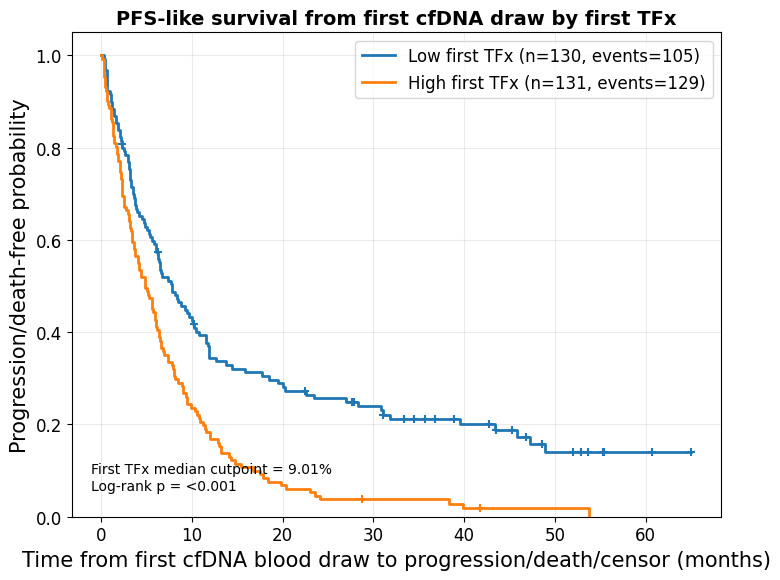


========== PFS1 KM summary ==========
first_TFx_group  n_patients  n_events  n_censored  median_PFS_from_first_draw_months  first_TFx_cutpoint  logrank_chi_square  logrank_p_value
  Low first TFx         130       105          25                           7.753593               9.006           22.090961         0.000003
 High first TFx         131       129           2                           4.796715               9.006           22.090961         0.000003

Saved KM plot:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis1_first_available_draw/PFS1_KM_from_first_draw_by_high_low_first_TFx.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis1_first_available_draw/PFS1_KM_from_first_draw_by_high_low_first_TFx.pdf

========== Cox model: first TFx continuous per 10% ==========
      covariate     coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%  cmp to        z            p  -log2(p)   

In [6]:
# ============================================================
# PFS Analysis 1
# First available cfDNA blood draw TFx vs time to next progression/death
# ============================================================
#
# Endpoint:
#   PFS-like interval from cfDNA blood draw to next documented progression or death.
#
# Primary analysis:
#   One row per patient = first available cfDNA blood draw
#
# Predictor:
#   TFx at first available blood draw
#
# Outcome:
#   PFS_time_from_draw = next progression/death/censor day - blood draw day
#
# Event:
#   1 = progression or death after blood draw
#   0 = censored at OS/follow-up day
#
# Important:
#   This is a cfDNA-indexed PFS-like endpoint, not trial-defined RECIST PFS.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

clinical_xlsx = BASE_DIR / "Clinical_data/AUP_ClinicalData_20260609.xlsx"
clinical_sheet = "AUP_ClinicalData_20260609.NO.DA"

blood_draws_xlsx = (
    BASE_DIR /
    "Clinical_data/All_cases_clinical_CNV_extraction_TSVs/"
    "All_cases_clinical_CNV_extraction.xlsx"
)
blood_draws_sheet = "Blood_draws"

out_dir = BASE_DIR / "Survival/PFS_Analysis1_first_available_draw"
out_dir.mkdir(parents=True, exist_ok=True)

print("Clinical file:")
print(clinical_xlsx)

print("\nBlood-draw file:")
print(blood_draws_xlsx)

print("\nOutput directory:")
print(out_dir)


# ============================================================
# 2. Helper functions
# ============================================================

def clean_patient_id(x):
    """
    Clean patient_id for matching across clinical and blood-draw files.

    Examples:
      2      -> "2"
      2.0    -> "2"
      "2.0"  -> "2"
      "999-17" -> "999-17"
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip()

    if s == "" or s.lower() in {"na", "nan", "none", "null"}:
        return pd.NA

    try:
        f = float(s)
        if f.is_integer():
            return str(int(f))
    except Exception:
        pass

    return s


def safe_numeric(x):
    return pd.to_numeric(x, errors="coerce")


def code_os_event(x):
    """
    Code OS_event.

    Dead                -> 1
    Alive with Disease  -> 0
    Lost to Follow Up   -> 0
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip().lower()

    if s == "dead":
        return 1

    if s in {"alive with disease", "lost to follow up", "lost to follow-up"}:
        return 0

    return pd.NA


def paste_unique(series, sep="; "):
    vals = []
    seen = set()

    for v in series:
        if pd.isna(v):
            continue

        s = str(v).strip()

        if s == "":
            continue

        if s not in seen:
            vals.append(s)
            seen.add(s)

    return sep.join(vals) if vals else pd.NA


def fmt_p(p):
    if pd.isna(p):
        return "NA"
    if p < 0.001:
        return "<0.001"
    return f"{p:.4f}"


# ============================================================
# 3. Read Blood_draws sheet
# ============================================================

blood = pd.read_excel(
    blood_draws_xlsx,
    sheet_name=blood_draws_sheet,
    dtype=str
)

print("\n========== Blood_draws input ==========")
print("Rows:", blood.shape[0])
print("Columns:", blood.shape[1])
print(blood.columns.tolist())

required_blood_cols = [
    "patient_id",
    "Patient_Identifier",
    "Barcode",
    "Blood_Draw_Days_From_Primary_Diagnosis",
    "Tumor_Fraction_percent_from_CNV_annotation",
    "Treatment_context_at_draw"
]

missing_blood_cols = [c for c in required_blood_cols if c not in blood.columns]

if len(missing_blood_cols) > 0:
    raise ValueError(f"Missing required Blood_draws columns: {missing_blood_cols}")

blood["patient_id_clean"] = blood["patient_id"].apply(clean_patient_id)

blood["blood_draw_day"] = safe_numeric(
    blood["Blood_Draw_Days_From_Primary_Diagnosis"]
)

blood["TFx"] = safe_numeric(
    blood["Tumor_Fraction_percent_from_CNV_annotation"]
)

# If TFx accidentally appears as 0-1 fraction, convert to percent
if blood["TFx"].dropna().shape[0] > 0:
    if blood["TFx"].dropna().max() <= 1:
        print("\nTFx appears to be 0-1 fraction; converting to percent.")
        blood["TFx"] = blood["TFx"] * 100

blood_draws = blood[
    blood["patient_id_clean"].notna()
    & blood["Barcode"].notna()
    & blood["blood_draw_day"].notna()
    & blood["TFx"].notna()
].copy()

blood_draws = blood_draws.rename(
    columns={
        "Patient_Identifier": "Patient_Identifier",
        "Barcode": "Barcode",
        "Treatment_context_at_draw": "Treatment_context_at_draw"
    }
)

print("\n========== Usable blood draws ==========")
print("Blood-draw rows:", blood_draws.shape[0])
print("Unique patients:", blood_draws["patient_id_clean"].nunique())
print("Unique barcodes:", blood_draws["Barcode"].nunique())
print("Rows with nonmissing TFx:", blood_draws["TFx"].notna().sum())

print("\nTreatment context distribution among usable blood draws:")
print(
    blood_draws["Treatment_context_at_draw"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)


# ============================================================
# 4. Read clinical file
# ============================================================

clinical = pd.read_excel(
    clinical_xlsx,
    sheet_name=clinical_sheet,
    dtype=str
)

print("\n========== Clinical input ==========")
print("Rows:", clinical.shape[0])
print("Columns:", clinical.shape[1])
print(clinical.columns.tolist())

required_clinical_cols = [
    "patient_id",
    "Category",
    "Days_From_Primary_Diagnosis",
    "EndTrt_Days_From_Primary_Diagnosis",
    "Treatment_Response",
    "OS_event"
]

missing_clinical_cols = [c for c in required_clinical_cols if c not in clinical.columns]

if len(missing_clinical_cols) > 0:
    raise ValueError(f"Missing required clinical columns: {missing_clinical_cols}")

clinical["patient_id_clean"] = clinical["patient_id"].apply(clean_patient_id)
clinical["Days_From_Primary_Diagnosis_num"] = safe_numeric(
    clinical["Days_From_Primary_Diagnosis"]
)
clinical["EndTrt_Days_From_Primary_Diagnosis_num"] = safe_numeric(
    clinical["EndTrt_Days_From_Primary_Diagnosis"]
)

# ============================================================
# Build receptor-status subgroup table
# ============================================================
#
# Subgroups:
#   HR+ HER2-
#   HR+ HER2+
#   HR- HER2-
#   HR- HER2+
#
# HR+ = ER positive OR PR positive
# HR- = ER negative AND PR negative
# HER2+ / HER2- based on HER2_Status
# ============================================================

required_receptor_cols = [
    "ER_Status",
    "PR_Status",
    "HER2_Status"
]

missing_receptor_cols = [c for c in required_receptor_cols if c not in clinical.columns]

if len(missing_receptor_cols) > 0:
    raise ValueError(f"Missing receptor-status columns: {missing_receptor_cols}")


def clean_receptor_status(x):
    """
    Standardize receptor status.

    Handles common values:
      Positive / Pos / +
      Negative / Neg / -
    """
    if pd.isna(x):
        return pd.NA

    s = str(x).strip().lower()

    if s == "" or s in {"na", "nan", "none", "null", "unknown"}:
        return pd.NA

    if s in {"positive", "pos", "+", "1", "yes"}:
        return "Positive"

    if s in {"negative", "neg", "-", "0", "no"}:
        return "Negative"

    # Extra protection for values like "ER positive", "HER2-positive"
    if "positive" in s or s.endswith("+"):
        return "Positive"

    if "negative" in s or s.endswith("-"):
        return "Negative"

    return pd.NA


def collapse_receptor_status(series):
    """
    Collapse receptor status to patient level.

    If any row is Positive, patient-level status is Positive.
    Else if any row is Negative, patient-level status is Negative.
    Else missing.
    """
    vals = series.dropna().astype(str).tolist()

    if "Positive" in vals:
        return "Positive"

    if "Negative" in vals:
        return "Negative"

    return pd.NA


def assign_subgroup(er_status, pr_status, her2_status):
    """
    Assign HR/HER2 subgroup.

    HR+  = ER+ or PR+
    HR-  = ER- and PR-
    HER2+ = HER2+
    HER2- = HER2-
    """
    if er_status == "Positive" or pr_status == "Positive":
        hr_status = "HR+"
    elif er_status == "Negative" and pr_status == "Negative":
        hr_status = "HR-"
    else:
        return pd.NA

    if her2_status == "Positive":
        her2_group = "HER2+"
    elif her2_status == "Negative":
        her2_group = "HER2-"
    else:
        return pd.NA

    return f"{hr_status} {her2_group}"


clinical_receptor = clinical[
    clinical["patient_id_clean"].notna()
].copy()

clinical_receptor["ER_Status_clean"] = clinical_receptor["ER_Status"].apply(clean_receptor_status)
clinical_receptor["PR_Status_clean"] = clinical_receptor["PR_Status"].apply(clean_receptor_status)
clinical_receptor["HER2_Status_clean"] = clinical_receptor["HER2_Status"].apply(clean_receptor_status)

patient_subgroups = (
    clinical_receptor
    .groupby("patient_id_clean", as_index=False)
    .agg(
        ER_Status_patient=("ER_Status_clean", collapse_receptor_status),
        PR_Status_patient=("PR_Status_clean", collapse_receptor_status),
        HER2_Status_patient=("HER2_Status_clean", collapse_receptor_status)
    )
)

patient_subgroups["Subgroups"] = patient_subgroups.apply(
    lambda r: assign_subgroup(
        r["ER_Status_patient"],
        r["PR_Status_patient"],
        r["HER2_Status_patient"]
    ),
    axis=1
)

patient_subgroups_file = out_dir / "PFS1_patient_level_receptor_subgroups.csv"
patient_subgroups.to_csv(patient_subgroups_file, index=False)

print("\n========== Patient-level receptor subgroups ==========")
print("Patients with receptor subgroup table:", patient_subgroups.shape[0])

print("\nSubgroup distribution:")
print(
    patient_subgroups["Subgroups"]
    .fillna("Missing/Unknown")
    .value_counts(dropna=False)
    .to_string()
)

print("\nSaved receptor subgroup table:")
print(patient_subgroups_file)

# ============================================================
# 5. Build progression-event table
# ============================================================
#
# Progression event day:
#   EndTrt_Days_From_Primary_Diagnosis from rows where
#   Treatment_Response == Progression
#
# Collapse duplicate rows from same patient/progression day.
# ============================================================

progression_rows = clinical[
    clinical["patient_id_clean"].notna()
    & clinical["Treatment_Response"].astype(str).str.strip().eq("Progression")
    & clinical["EndTrt_Days_From_Primary_Diagnosis_num"].notna()
].copy()

progression_rows["progression_day"] = progression_rows[
    "EndTrt_Days_From_Primary_Diagnosis_num"
]

progression_events = (
    progression_rows
    .groupby(["patient_id_clean", "progression_day"], dropna=False)
    .agg(
        progression_categories=("Category", paste_unique),
        progression_lines=("Met_Therapy_Line", paste_unique),
        progression_regimens=("Regimen", paste_unique),
        n_progression_rows=("Treatment_Response", "size")
    )
    .reset_index()
)

progression_events_file = out_dir / "PFS1_progression_event_days_collapsed.csv"
progression_events.to_csv(progression_events_file, index=False)

print("\n========== Progression event table ==========")
print("Progression rows:", progression_rows.shape[0])
print("Collapsed progression patient-days:", progression_events.shape[0])
print("Patients with progression events:", progression_events["patient_id_clean"].nunique())

print("\nPreview progression events:")
print(progression_events.head(20).to_string(index=False))


# ============================================================
# 6. Build OS/death/follow-up table
# ============================================================
#
# OS row:
#   Category == Overall_Survival_days
#
# OS_event:
#   Dead = death event
#   Alive with Disease / Lost to Follow Up = censored
# ============================================================

os_rows = clinical[
    clinical["patient_id_clean"].notna()
    & clinical["Category"].astype(str).str.strip().eq("Overall_Survival_days")
].copy()

os_rows["OS_days"] = os_rows["Days_From_Primary_Diagnosis_num"]
os_rows["OS_event_coded"] = os_rows["OS_event"].apply(code_os_event)

print("\n========== OS rows ==========")
print("OS rows:", os_rows.shape[0])
print("Unique patients with OS rows:", os_rows["patient_id_clean"].nunique())

print("\nRaw OS_event distribution:")
print(os_rows["OS_event"].fillna("Missing").value_counts(dropna=False).to_string())

print("\nCoded OS_event distribution:")
print(os_rows["OS_event_coded"].fillna("Missing").value_counts(dropna=False).to_string())

os_patient_rows = []

for pid, sub in os_rows.groupby("patient_id_clean", dropna=False):
    if pd.isna(pid):
        continue

    os_days = sub["OS_days"].max(skipna=True)

    event_vals = sub["OS_event_coded"].dropna().astype(int).tolist()

    if 1 in event_vals:
        os_event = 1
        death_day = os_days
    elif 0 in event_vals:
        os_event = 0
        death_day = np.nan
    else:
        os_event = pd.NA
        death_day = np.nan

    os_patient_rows.append({
        "patient_id_clean": pid,
        "OS_days": os_days,
        "OS_event": os_event,
        "death_day": death_day,
        "OS_event_raw_all": paste_unique(sub["OS_event"]),
        "n_OS_rows": sub.shape[0]
    })

os_patient = pd.DataFrame(os_patient_rows)

os_patient_file = out_dir / "PFS1_patient_level_OS_followup_death.csv"
os_patient.to_csv(os_patient_file, index=False)

print("\n========== Patient-level OS/follow-up table ==========")
print("Patients:", os_patient.shape[0])
print("Deaths:", int((os_patient["OS_event"] == 1).sum()))
print("Censored/alive/LTFU:", int((os_patient["OS_event"] == 0).sum()))
print("Missing OS_event:", os_patient["OS_event"].isna().sum())

print("\nPreview OS patient table:")
print(os_patient.head(20).to_string(index=False))


# ============================================================
# 7. Build blood-draw-level PFS table
# ============================================================
#
# For each blood draw:
#   next_progression_day = first progression day > blood_draw_day
#   death_day = OS_days if Dead and death_day > blood_draw_day
#
#   PFS event day = earliest(next_progression_day, death_day)
#
# If no event:
#   censor at OS_days if OS_days > blood_draw_day
#
# Important:
#   This uses strictly future events only: event_day > blood_draw_day.
# ============================================================

progression_by_patient = {
    pid: np.sort(sub["progression_day"].dropna().unique())
    for pid, sub in progression_events.groupby("patient_id_clean")
}

os_by_patient = os_patient.set_index("patient_id_clean").to_dict(orient="index")

pfs_rows = []

for _, row in blood_draws.iterrows():
    pid = row["patient_id_clean"]
    draw_day = row["blood_draw_day"]

    # -------------------------
    # Next progression after draw
    # -------------------------
    prog_days = progression_by_patient.get(pid, np.array([]))

    future_prog_days = prog_days[prog_days > draw_day]

    if len(future_prog_days) > 0:
        next_prog_day = float(future_prog_days[0])
    else:
        next_prog_day = np.nan

    # -------------------------
    # Death/follow-up
    # -------------------------
    os_info = os_by_patient.get(pid, {})

    os_days = os_info.get("OS_days", np.nan)
    os_event = os_info.get("OS_event", pd.NA)
    death_day = os_info.get("death_day", np.nan)
    os_event_raw_all = os_info.get("OS_event_raw_all", pd.NA)

    future_death_day = np.nan

    if pd.notna(death_day) and pd.notna(draw_day):
        if death_day > draw_day:
            future_death_day = float(death_day)

    # -------------------------
    # Determine event day/type
    # -------------------------
    candidate_events = []

    if pd.notna(next_prog_day):
        candidate_events.append(("Progression", next_prog_day))

    if pd.notna(future_death_day):
        candidate_events.append(("Death", future_death_day))

    if len(candidate_events) > 0:
        # Earliest event wins
        candidate_events = sorted(candidate_events, key=lambda x: x[1])
        pfs_event_type = candidate_events[0][0]
        pfs_event_day = candidate_events[0][1]
        pfs_event = 1
        pfs_time = pfs_event_day - draw_day
        censor_day = np.nan

    else:
        pfs_event_type = "Censored"
        pfs_event_day = np.nan
        pfs_event = 0

        if pd.notna(os_days) and os_days > draw_day:
            censor_day = float(os_days)
            pfs_time = censor_day - draw_day
        else:
            censor_day = np.nan
            pfs_time = np.nan

    # -------------------------
    # QC flag
    # -------------------------
    qc_flags = []

    if pd.isna(os_days):
        qc_flags.append("Missing OS/follow-up day")

    if pd.notna(os_days) and os_days <= draw_day:
        qc_flags.append("OS/follow-up day <= blood draw day; no follow-up after draw")

    if pd.notna(pfs_time) and pfs_time < 0:
        qc_flags.append("Negative PFS time")

    if pd.notna(pfs_time) and pfs_time == 0:
        qc_flags.append("Zero PFS time")

    qc_flag = "; ".join(qc_flags) if len(qc_flags) > 0 else pd.NA

    pfs_rows.append({
        "patient_id": row["patient_id"],
        "patient_id_clean": pid,
        "Patient_Identifier": row.get("Patient_Identifier", pd.NA),
        "Barcode": row["Barcode"],
        "blood_draw_day": draw_day,
        "TFx": row["TFx"],
        "Treatment_context_at_draw": row.get("Treatment_context_at_draw", pd.NA),
        "Active_treatment_at_draw": row.get("Active_treatment_at_draw", pd.NA),
        "draw_num": row.get("draw_num", pd.NA),
        "next_progression_day_after_draw": next_prog_day,
        "death_day_after_draw": future_death_day,
        "OS_days_or_last_followup": os_days,
        "OS_event_raw_all": os_event_raw_all,
        "PFS_event_day": pfs_event_day,
        "PFS_censor_day": censor_day,
        "PFS_time_from_draw": pfs_time,
        "PFS_event": pfs_event,
        "PFS_event_type": pfs_event_type,
        "PFS_QC_Flag": qc_flag
    })

blood_draw_pfs = pd.DataFrame(pfs_rows)

blood_draw_pfs_file = out_dir / "PFS1_blood_draw_level_TFx_PFS_from_draw.csv"
blood_draw_pfs.to_csv(blood_draw_pfs_file, index=False)

print("\n========== Blood-draw-level PFS table ==========")
print("Rows:", blood_draw_pfs.shape[0])
print("Patients:", blood_draw_pfs["patient_id_clean"].nunique())
print("Rows with PFS time:", blood_draw_pfs["PFS_time_from_draw"].notna().sum())

print("\nPFS event type distribution:")
print(
    blood_draw_pfs["PFS_event_type"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

print("\nPFS QC flag distribution:")
print(
    blood_draw_pfs["PFS_QC_Flag"]
    .fillna("No QC flag")
    .value_counts(dropna=False)
    .head(20)
    .to_string()
)

print("\nPreview blood-draw-level PFS:")
print(
    blood_draw_pfs[
        [
            "patient_id",
            "Barcode",
            "blood_draw_day",
            "TFx",
            "Treatment_context_at_draw",
            "next_progression_day_after_draw",
            "death_day_after_draw",
            "PFS_event_day",
            "PFS_time_from_draw",
            "PFS_event",
            "PFS_event_type",
            "PFS_QC_Flag"
        ]
    ]
    .head(30)
    .to_string(index=False)
)


# ============================================================
# 8. Create Analysis 1 patient-level table:
#    first available eligible cfDNA blood draw per patient
# ============================================================
#
# Eligibility:
#   - nonmissing TFx
#   - nonmissing blood_draw_day
#   - nonmissing PFS_time_from_draw
#   - PFS_time_from_draw > 0
# ============================================================

eligible_draws = blood_draw_pfs[
    blood_draw_pfs["TFx"].notna()
    & blood_draw_pfs["blood_draw_day"].notna()
    & blood_draw_pfs["PFS_time_from_draw"].notna()
    & (blood_draw_pfs["PFS_time_from_draw"] > 0)
].copy()

eligible_draws = eligible_draws.sort_values(
    ["patient_id_clean", "blood_draw_day", "Barcode"]
)

first_draw = (
    eligible_draws
    .groupby("patient_id_clean", as_index=False)
    .first()
)

first_draw = first_draw.rename(
    columns={
        "blood_draw_day": "first_draw_day",
        "Barcode": "first_draw_barcode",
        "TFx": "first_TFx",
        "Treatment_context_at_draw": "Treatment_context_at_first_draw",
        "Active_treatment_at_draw": "Active_treatment_at_first_draw",
        "PFS_time_from_draw": "PFS_time_from_first_draw",
        "PFS_event": "PFS_event_from_first_draw",
        "PFS_event_type": "PFS_event_type_from_first_draw"
    }
)
# Add receptor subgroup annotation to first-draw patient-level table
first_draw = first_draw.merge(
    patient_subgroups[
        [
            "patient_id_clean",
            "Subgroups"
        ]
    ],
    on="patient_id_clean",
    how="left"
)

print("\nSubgroup distribution in first-draw PFS table:")
print(
    first_draw["Subgroups"]
    .fillna("Missing/Unknown")
    .value_counts(dropna=False)
    .to_string()
)

first_draw_file = out_dir / "PFS1_first_available_draw_per_patient.csv"
first_draw.to_csv(first_draw_file, index=False)

print("\n========== PFS Analysis 1: first available draw ==========")
print("Patients:", first_draw.shape[0])
print("Events:", int((first_draw["PFS_event_from_first_draw"] == 1).sum()))
print("Censored:", int((first_draw["PFS_event_from_first_draw"] == 0).sum()))

print("\nEvent type distribution:")
print(
    first_draw["PFS_event_type_from_first_draw"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

print("\nTreatment context at first draw:")
print(
    first_draw["Treatment_context_at_first_draw"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

print("\nPreview first-draw PFS table:")
print(
    first_draw[
        [
            "patient_id",
            "Patient_Identifier",
            "first_draw_barcode",
            "first_draw_day",
            "first_TFx",
            "Treatment_context_at_first_draw",
            "PFS_time_from_first_draw",
            "PFS_event_from_first_draw",
            "PFS_event_type_from_first_draw"
        ]
    ]
    .head(30)
    .to_string(index=False)
)


# ============================================================
# 9. High vs low first TFx group
# ============================================================

if first_draw.shape[0] == 0:
    raise RuntimeError("No eligible first-draw PFS rows available.")

first_tfx_cut = first_draw["first_TFx"].median()

first_draw["first_TFx_group"] = np.where(
    first_draw["first_TFx"] >= first_tfx_cut,
    "High first TFx",
    "Low first TFx"
)

print("\n========== First TFx grouping ==========")
print(f"Median first TFx cutpoint: {first_tfx_cut:.4f}%")
print(first_draw["first_TFx_group"].value_counts().to_string())

first_draw.to_csv(first_draw_file, index=False)


# ============================================================
# 10. KM and log-rank helper functions
# ============================================================

def km_curve(durations, events):
    """
    Manual Kaplan-Meier estimator.
    """
    data = pd.DataFrame({
        "time": pd.to_numeric(durations, errors="coerce"),
        "event": pd.to_numeric(events, errors="coerce")
    }).dropna()

    data = data.sort_values("time")

    event_times = sorted(data.loc[data["event"] == 1, "time"].unique())

    x = [0.0]
    y = [1.0]

    surv_prob = 1.0
    median_survival = np.nan
    rows = []

    for t in event_times:
        n_at_risk = int((data["time"] >= t).sum())
        n_events = int(((data["time"] == t) & (data["event"] == 1)).sum())
        n_censored = int(((data["time"] == t) & (data["event"] == 0)).sum())

        if n_at_risk > 0:
            surv_prob = surv_prob * (1 - n_events / n_at_risk)

        x.append(float(t))
        y.append(float(surv_prob))

        rows.append({
            "time": t,
            "n_at_risk": n_at_risk,
            "n_events": n_events,
            "n_censored": n_censored,
            "survival": surv_prob
        })

        if pd.isna(median_survival) and surv_prob <= 0.5:
            median_survival = t

    max_time = data["time"].max()

    if len(x) == 1 or x[-1] < max_time:
        x.append(float(max_time))
        y.append(float(surv_prob))

    return np.array(x), np.array(y), pd.DataFrame(rows), median_survival


def survival_at_censor_times(event_table, censor_times):
    surv_vals = []

    for t in censor_times:
        sub = event_table[event_table["time"] <= t]

        if sub.empty:
            surv_vals.append(1.0)
        else:
            surv_vals.append(float(sub.iloc[-1]["survival"]))

    return np.array(surv_vals)


def logrank_two_group(df, time_col, event_col, group_col, group_a, group_b):
    d = df[df[group_col].isin([group_a, group_b])].copy()

    event_times = sorted(d.loc[d[event_col] == 1, time_col].dropna().unique())

    O_a = 0.0
    E_a = 0.0
    V_a = 0.0

    for t in event_times:
        n_a = ((d[group_col] == group_a) & (d[time_col] >= t)).sum()
        n_b = ((d[group_col] == group_b) & (d[time_col] >= t)).sum()
        n_total = n_a + n_b

        d_a = (
            (d[group_col] == group_a)
            & (d[time_col] == t)
            & (d[event_col] == 1)
        ).sum()

        d_b = (
            (d[group_col] == group_b)
            & (d[time_col] == t)
            & (d[event_col] == 1)
        ).sum()

        d_total = d_a + d_b

        if n_total <= 1 or d_total == 0:
            continue

        e_a = d_total * (n_a / n_total)

        v_a = (
            n_a * n_b * d_total * (n_total - d_total)
        ) / (
            (n_total ** 2) * (n_total - 1)
        )

        O_a += d_a
        E_a += e_a
        V_a += v_a

    if V_a > 0:
        chi_sq = ((O_a - E_a) ** 2) / V_a
        p_value = chi2.sf(chi_sq, df=1)
    else:
        chi_sq = np.nan
        p_value = np.nan

    return chi_sq, p_value

# ============================================================
# Convert PFS time from days to months for plotting/reporting
# ============================================================

DAYS_PER_MONTH = 365.25 / 12

first_draw["PFS_time_from_first_draw_months"] = (
    first_draw["PFS_time_from_first_draw"] / DAYS_PER_MONTH
)

blood_draw_pfs["PFS_time_from_draw_months"] = (
    blood_draw_pfs["PFS_time_from_draw"] / DAYS_PER_MONTH
)

# Save updated tables with month columns
blood_draw_pfs.to_csv(blood_draw_pfs_file, index=False)
first_draw.to_csv(first_draw_file, index=False)

print("\n========== PFS time converted to months ==========")
print(f"Days per month used: {DAYS_PER_MONTH:.4f}")

print("\nPreview first-draw PFS time in days and months:")
print(
    first_draw[
        [
            "patient_id",
            "first_draw_barcode",
            "first_draw_day",
            "first_TFx",
            "PFS_time_from_first_draw",
            "PFS_time_from_first_draw_months",
            "PFS_event_from_first_draw",
            "PFS_event_type_from_first_draw"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

# ============================================================
# 11. KM plot: high vs low first TFx
# ============================================================

time_col = "PFS_time_from_first_draw_months"
event_col = "PFS_event_from_first_draw"
group_col = "first_TFx_group"

chi_sq, logrank_p = logrank_two_group(
    first_draw,
    time_col=time_col,
    event_col=event_col,
    group_col=group_col,
    group_a="Low first TFx",
    group_b="High first TFx"
)

group_order = ["Low first TFx", "High first TFx"]

km_summary_rows = []

fig, ax = plt.subplots(figsize=(7.5, 6))

for group in group_order:
    sub = first_draw[first_draw[group_col] == group].copy()

    x, y, event_table, median_pfs = km_curve(
        sub[time_col],
        sub[event_col]
    )

    n_patients = sub.shape[0]
    n_events = int((sub[event_col] == 1).sum())
    n_censored = int((sub[event_col] == 0).sum())

    ax.step(
        x,
        y,
        where="post",
        linewidth=2,
        label=f"{group} (n={n_patients}, events={n_events})"
    )

    censor_times = sub.loc[sub[event_col] == 0, time_col].dropna().values
    censor_y = survival_at_censor_times(event_table, censor_times)

    if len(censor_times) > 0:
        ax.scatter(
            censor_times,
            censor_y,
            marker="+",
            s=35
        )

    km_summary_rows.append({
        "first_TFx_group": group,
        "n_patients": n_patients,
        "n_events": n_events,
        "n_censored": n_censored,
        "median_PFS_from_first_draw_months": median_pfs,
        "first_TFx_cutpoint": first_tfx_cut,
        "logrank_chi_square": chi_sq,
        "logrank_p_value": logrank_p
    })

ax.set_title(
    "PFS-like survival from first cfDNA draw by first TFx",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Time from first cfDNA blood draw to progression/death/censor (months)")
ax.set_ylabel("Progression/death-free probability")

ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)

ax.text(
    0.03,
    0.05,
    f"First TFx median cutpoint = {first_tfx_cut:.2f}%\nLog-rank p = {fmt_p(logrank_p)}",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10
)

ax.legend(loc="best")

plt.tight_layout()

km_png = out_dir / "PFS1_KM_from_first_draw_by_high_low_first_TFx.png"
km_pdf = out_dir / "PFS1_KM_from_first_draw_by_high_low_first_TFx.pdf"

plt.savefig(km_png, dpi=300)
plt.savefig(km_pdf)

plt.show()

plt.close()

km_summary = pd.DataFrame(km_summary_rows)

km_summary_file = out_dir / "PFS1_KM_summary_from_first_draw_by_first_TFx.csv"
km_summary.to_csv(km_summary_file, index=False)

print("\n========== PFS1 KM summary ==========")
print(km_summary.to_string(index=False))

print("\nSaved KM plot:")
print(km_png)
print(km_pdf)


# ============================================================
# 12. Optional Cox model using lifelines if available
# ============================================================

try:
    from lifelines import CoxPHFitter

    cox_input = first_draw[
        [
            "PFS_time_from_first_draw",
            "PFS_event_from_first_draw",
            "first_TFx",
            "first_TFx_group"
        ]
    ].copy()

    cox_input["first_TFx_per10"] = cox_input["first_TFx"] / 10.0
    cox_input["High_first_TFx"] = (
        cox_input["first_TFx_group"] == "High first TFx"
    ).astype(int)

    # Continuous Cox: per 10% TFx increase
    cph = CoxPHFitter()
    cph.fit(
        cox_input[
            [
                "PFS_time_from_first_draw",
                "PFS_event_from_first_draw",
                "first_TFx_per10"
            ]
        ],
        duration_col="PFS_time_from_first_draw",
        event_col="PFS_event_from_first_draw"
    )

    cox_cont = cph.summary.reset_index()
    cox_cont["model"] = "Cox: PFS ~ first_TFx_per10"

    cox_cont_file = out_dir / "PFS1_Cox_continuous_first_TFx_per10.csv"
    cox_cont.to_csv(cox_cont_file, index=False)

    print("\n========== Cox model: first TFx continuous per 10% ==========")
    print(cox_cont.to_string(index=False))

    # High vs low Cox
    cph2 = CoxPHFitter()
    cph2.fit(
        cox_input[
            [
                "PFS_time_from_first_draw",
                "PFS_event_from_first_draw",
                "High_first_TFx"
            ]
        ],
        duration_col="PFS_time_from_first_draw",
        event_col="PFS_event_from_first_draw"
    )

    cox_group = cph2.summary.reset_index()
    cox_group["model"] = "Cox: PFS ~ High_first_TFx"
    cox_group["first_TFx_cutpoint"] = first_tfx_cut

    cox_group_file = out_dir / "PFS1_Cox_high_vs_low_first_TFx.csv"
    cox_group.to_csv(cox_group_file, index=False)

    print("\n========== Cox model: high vs low first TFx ==========")
    print(cox_group.to_string(index=False))

except ImportError:
    print("\nWARNING: lifelines is not installed. Skipping Cox models.")
    print("To run Cox models, install lifelines in your environment:")
    print("python -m pip install lifelines")

except Exception as e:
    print("\nCox model failed:")
    print(e)


# ============================================================
# 13. Final interpretation note
# ============================================================

note_file = out_dir / "PFS1_interpretation_note.txt"

with open(note_file, "w") as f:
    f.write("PFS Analysis 1: first available cfDNA blood draw TFx\n")
    f.write("====================================================\n\n")

    f.write("Endpoint definition:\n")
    f.write(
        "PFS-like survival was defined from the first available cfDNA blood draw "
        "to the next documented progression or death. Patients without subsequent "
        "progression/death were censored at OS/follow-up day.\n\n"
    )

    f.write("Progression definition:\n")
    f.write(
        "Progression events were extracted from clinical treatment rows where "
        "Treatment_Response == Progression, using EndTrt_Days_From_Primary_Diagnosis "
        "as the progression day.\n\n"
    )

    f.write("Primary predictor:\n")
    f.write("TFx at first available cfDNA blood draw.\n\n")

    f.write("Cohort summary:\n")
    f.write(f"Eligible first-draw patients: {first_draw.shape[0]}\n")
    f.write(f"Events: {int((first_draw['PFS_event_from_first_draw'] == 1).sum())}\n")
    f.write(f"Censored: {int((first_draw['PFS_event_from_first_draw'] == 0).sum())}\n")
    f.write(f"First TFx median cutpoint: {first_tfx_cut:.4f}%\n")
    f.write(f"Log-rank p-value: {logrank_p:.6g}\n\n")

    f.write("Important caveat:\n")
    f.write(
        "This is a cfDNA-indexed PFS-like endpoint based on available clinical "
        "progression annotations and should not be described as trial-defined\n"
    )

print("\n========== PFS Analysis 1 complete ==========")
print("Main files:")
print(blood_draw_pfs_file)
print(first_draw_file)
print(km_summary_file)
print(note_file)

print("\nMain plot:")
print(km_png)

In [5]:
# ============================================================
# QC: Identify patients with TFx but excluded from first-draw PFS KM
# ============================================================

all_tfx_patients = set(blood_draws["patient_id_clean"].dropna().astype(str))
eligible_pfs_patients = set(first_draw["patient_id_clean"].dropna().astype(str))

excluded_patients = sorted(list(all_tfx_patients - eligible_pfs_patients))

print("\n========== Patients with TFx but excluded from first-draw PFS KM ==========")
print("All TFx patients:", len(all_tfx_patients))
print("Eligible first-draw PFS patients:", len(eligible_pfs_patients))
print("Excluded patients:", len(excluded_patients))
print(excluded_patients)

print("\nDetails for excluded patients:")
print(
    blood_draw_pfs[
        blood_draw_pfs["patient_id_clean"].astype(str).isin(excluded_patients)
    ][
        [
            "patient_id",
            "Barcode",
            "blood_draw_day",
            "TFx",
            "OS_days_or_last_followup",
            "PFS_time_from_draw",
            "PFS_event",
            "PFS_event_type",
            "PFS_QC_Flag"
        ]
    ].to_string(index=False)
)


========== Patients with TFx but excluded from first-draw PFS KM ==========
All TFx patients: 262
Eligible first-draw PFS patients: 261
Excluded patients: 1
['993-24']

Details for excluded patients:
patient_id  Barcode  blood_draw_day   TFx  OS_days_or_last_followup  PFS_time_from_draw  PFS_event PFS_event_type                                                 PFS_QC_Flag
    993-24 AOO9-NB1              71 47.24                      71.0                 NaN          0       Censored OS/follow-up day <= blood draw day; no follow-up after draw


Input blood-draw-level PFS file:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis1_first_available_draw/PFS1_blood_draw_level_TFx_PFS_from_draw.csv

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis2_first_on_treatment_draw

========== Input PFS1 blood-draw-level table ==========
Rows: 769
Columns: 20
['patient_id', 'patient_id_clean', 'Patient_Identifier', 'Barcode', 'blood_draw_day', 'TFx', 'Treatment_context_at_draw', 'Active_treatment_at_draw', 'draw_num', 'next_progression_day_after_draw', 'death_day_after_draw', 'OS_days_or_last_followup', 'OS_event_raw_all', 'PFS_event_day', 'PFS_censor_day', 'PFS_time_from_draw', 'PFS_event', 'PFS_event_type', 'PFS_QC_Flag', 'PFS_time_from_draw_months']

Unique patients in blood-draw-level table:
262

Treatment_context_at_draw distribution:
On-treatment                    491
Between-treatment-lines         129
Pre-treatment                    74
Post-treatment                

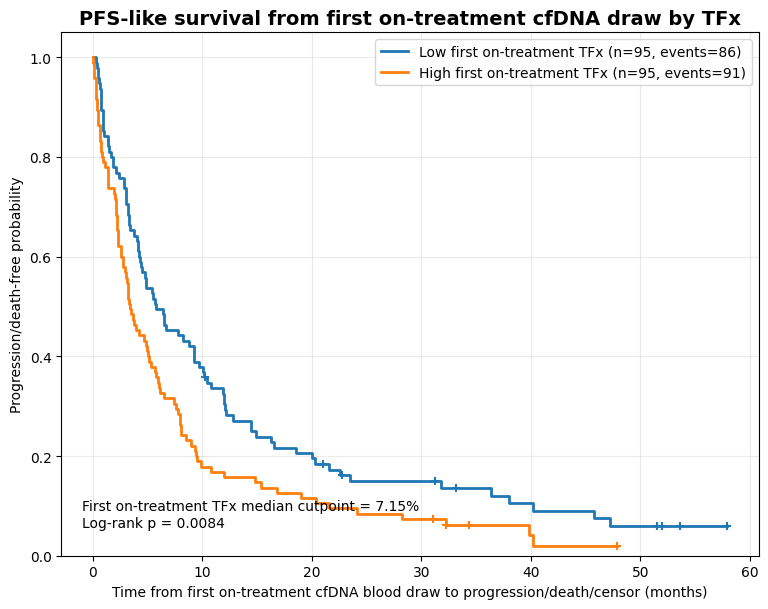


========== PFS2 KM summary ==========
first_on_treatment_TFx_group  n_patients  n_events  n_censored  median_PFS_from_first_on_treatment_draw_months  first_on_treatment_TFx_cutpoint  logrank_chi_square  logrank_p_value
  Low first on-treatment TFx          95        86           9                                        5.782341                            7.152            6.936725         0.008444
 High first on-treatment TFx          95        91           4                                        3.416838                            7.152            6.936725         0.008444

Saved KM plot:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis2_first_on_treatment_draw/PFS2_KM_from_first_on_treatment_draw_by_high_low_TFx.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Survival/PFS_Analysis2_first_on_treatment_draw/PFS2_KM_from_first_on_treatment_draw_by_high_low_TFx.pdf

========== Number-at-risk table ==========
                      group  time_days  n_at

In [6]:
# ============================================================
# PFS Analysis 2
# First ON-TREATMENT cfDNA blood draw TFx vs PFS-like survival
# ============================================================
#
# This script continues from Analysis 1 output:
#   PFS1_blood_draw_level_TFx_PFS_from_draw.csv
#
# Endpoint:
#   Time from first ON-TREATMENT cfDNA blood draw
#   to next documented progression or death.
#
# Primary predictor:
#   TFx at first on-treatment cfDNA blood draw.
#
# Unit of analysis:
#   One row per patient.
#
# Why this analysis:
#   Analysis 1 used first available draw, which may occur in different
#   clinical states. Analysis 2 restricts to on-treatment draws, so the
#   interpretation is more clinically focused.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2


# ============================================================
# 1. Paths
# ============================================================

BASE_DIR = Path("/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA")

pfs1_dir = BASE_DIR / "Survival/PFS_Analysis1_first_available_draw"

pfs1_blood_draw_file = (
    pfs1_dir / "PFS1_blood_draw_level_TFx_PFS_from_draw.csv"
)

out_dir = BASE_DIR / "Survival/PFS_Analysis2_first_on_treatment_draw"
out_dir.mkdir(parents=True, exist_ok=True)

print("Input blood-draw-level PFS file:")
print(pfs1_blood_draw_file)

print("\nOutput directory:")
print(out_dir)

if not pfs1_blood_draw_file.exists():
    raise FileNotFoundError(
        f"Cannot find Analysis 1 blood-draw-level PFS file:\n{pfs1_blood_draw_file}"
    )


# ============================================================
# 2. Helper functions
# ============================================================

def safe_numeric(x):
    return pd.to_numeric(x, errors="coerce")


def norm_str(x):
    if pd.isna(x):
        return ""

    s = str(x).strip()

    if s.lower() in {"", "na", "nan", "none", "null", "<na>"}:
        return ""

    return s


def fmt_p(p):
    if pd.isna(p):
        return "NA"
    if p < 0.001:
        return "<0.001"
    return f"{p:.4f}"


def classify_on_treatment(row):
    """
    Classify whether a blood draw occurred on active treatment.

    This uses both:
      1. Treatment_context_at_draw
      2. Active_treatment_at_draw

    The function is intentionally conservative for pre/off/post-treatment labels.
    """

    context = norm_str(row.get("Treatment_context_at_draw", "")).lower()
    active = norm_str(row.get("Active_treatment_at_draw", "")).lower()

    # -------------------------
    # Exclusion terms
    # -------------------------
    # These should NOT be counted as on-treatment.
    off_terms = [
        "pre-treatment",
        "pre treatment",
        "pretreatment",
        "before treatment",
        "post-treatment",
        "post treatment",
        "off-treatment",
        "off treatment",
        "after treatment",
        "between treatment",
        "between treatments",
        "no active treatment",
        "not on treatment"
    ]

    if any(term in context for term in off_terms):
        return False, "Excluded by Treatment_context_at_draw"

    if any(term in active for term in ["no active", "not active", "none", "no treatment"]):
        return False, "Excluded by Active_treatment_at_draw"

    # -------------------------
    # Inclusion terms from treatment context
    # -------------------------
    on_context_terms = [
        "on-treatment",
        "on treatment",
        "during treatment",
        "active treatment"
    ]

    if any(term in context for term in on_context_terms):
        return True, "Included by Treatment_context_at_draw"

    # -------------------------
    # Inclusion terms from active treatment column
    # -------------------------
    # If Active_treatment_at_draw is yes-like, include.
    if active in {"yes", "y", "true", "1"}:
        return True, "Included by Active_treatment_at_draw yes-like value"

    # If Active_treatment_at_draw contains a regimen/drug name, it may be non-empty.
    # We include non-empty active-treatment entries unless they were excluded above.
    if active != "":
        return True, "Included by nonempty Active_treatment_at_draw"

    return False, "Not classified as on-treatment"


def km_curve(durations, events):
    """
    Manual Kaplan-Meier estimator.
    """

    data = pd.DataFrame({
        "time": pd.to_numeric(durations, errors="coerce"),
        "event": pd.to_numeric(events, errors="coerce")
    }).dropna()

    data = data.sort_values("time")

    event_times = sorted(data.loc[data["event"] == 1, "time"].unique())

    x = [0.0]
    y = [1.0]

    surv_prob = 1.0
    median_survival = np.nan
    rows = []

    for t in event_times:
        n_at_risk = int((data["time"] >= t).sum())
        n_events = int(((data["time"] == t) & (data["event"] == 1)).sum())
        n_censored = int(((data["time"] == t) & (data["event"] == 0)).sum())

        if n_at_risk > 0:
            surv_prob = surv_prob * (1 - n_events / n_at_risk)

        x.append(float(t))
        y.append(float(surv_prob))

        rows.append({
            "time": t,
            "n_at_risk": n_at_risk,
            "n_events": n_events,
            "n_censored": n_censored,
            "survival": surv_prob
        })

        if pd.isna(median_survival) and surv_prob <= 0.5:
            median_survival = t

    max_time = data["time"].max()

    if len(x) == 1 or x[-1] < max_time:
        x.append(float(max_time))
        y.append(float(surv_prob))

    return np.array(x), np.array(y), pd.DataFrame(rows), median_survival


def survival_at_censor_times(event_table, censor_times):
    surv_vals = []

    for t in censor_times:
        sub = event_table[event_table["time"] <= t]

        if sub.empty:
            surv_vals.append(1.0)
        else:
            surv_vals.append(float(sub.iloc[-1]["survival"]))

    return np.array(surv_vals)


def logrank_two_group(df, time_col, event_col, group_col, group_a, group_b):
    """
    Two-group log-rank test.
    """

    d = df[df[group_col].isin([group_a, group_b])].copy()

    d[time_col] = pd.to_numeric(d[time_col], errors="coerce")
    d[event_col] = pd.to_numeric(d[event_col], errors="coerce")

    d = d.dropna(subset=[time_col, event_col, group_col])

    event_times = sorted(d.loc[d[event_col] == 1, time_col].unique())

    O_a = 0.0
    E_a = 0.0
    V_a = 0.0

    for t in event_times:
        n_a = ((d[group_col] == group_a) & (d[time_col] >= t)).sum()
        n_b = ((d[group_col] == group_b) & (d[time_col] >= t)).sum()
        n_total = n_a + n_b

        d_a = (
            (d[group_col] == group_a)
            & (d[time_col] == t)
            & (d[event_col] == 1)
        ).sum()

        d_b = (
            (d[group_col] == group_b)
            & (d[time_col] == t)
            & (d[event_col] == 1)
        ).sum()

        d_total = d_a + d_b

        if n_total <= 1 or d_total == 0:
            continue

        e_a = d_total * (n_a / n_total)

        v_a = (
            n_a * n_b * d_total * (n_total - d_total)
        ) / (
            (n_total ** 2) * (n_total - 1)
        )

        O_a += d_a
        E_a += e_a
        V_a += v_a

    if V_a > 0:
        chi_sq = ((O_a - E_a) ** 2) / V_a
        p_value = chi2.sf(chi_sq, df=1)
    else:
        chi_sq = np.nan
        p_value = np.nan

    return chi_sq, p_value


# ============================================================
# 3. Read Analysis 1 blood-draw-level PFS table
# ============================================================

pfs = pd.read_csv(pfs1_blood_draw_file, dtype=str)

print("\n========== Input PFS1 blood-draw-level table ==========")
print("Rows:", pfs.shape[0])
print("Columns:", pfs.shape[1])
print(pfs.columns.tolist())

required_cols = [
    "patient_id_clean",
    "patient_id",
    "Barcode",
    "blood_draw_day",
    "TFx",
    "Treatment_context_at_draw",
    "PFS_time_from_draw",
    "PFS_event",
    "PFS_event_type"
]

missing_cols = [c for c in required_cols if c not in pfs.columns]

if len(missing_cols) > 0:
    raise ValueError(f"Missing required columns from PFS1 table: {missing_cols}")

# Numeric conversion
for col in [
    "blood_draw_day",
    "TFx",
    "PFS_time_from_draw",
    "PFS_event",
    "PFS_event_day",
    "PFS_censor_day",
    "next_progression_day_after_draw",
    "death_day_after_draw",
    "OS_days_or_last_followup"
]:
    if col in pfs.columns:
        pfs[col] = safe_numeric(pfs[col])

print("\nUnique patients in blood-draw-level table:")
print(pfs["patient_id_clean"].nunique())

print("\nTreatment_context_at_draw distribution:")
print(
    pfs["Treatment_context_at_draw"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

if "Active_treatment_at_draw" in pfs.columns:
    print("\nTop Active_treatment_at_draw values:")
    print(
        pfs["Active_treatment_at_draw"]
        .fillna("Missing")
        .value_counts(dropna=False)
        .head(30)
        .to_string()
    )


# ============================================================
# 4. Classify on-treatment blood draws
# ============================================================

classification = pfs.apply(classify_on_treatment, axis=1)

pfs["is_on_treatment_draw"] = [x[0] for x in classification]
pfs["on_treatment_classification_reason"] = [x[1] for x in classification]

classification_qc_file = out_dir / "PFS2_on_treatment_classification_QC_all_draws.csv"
pfs.to_csv(classification_qc_file, index=False)

print("\n========== On-treatment classification summary ==========")
print(pfs["is_on_treatment_draw"].value_counts(dropna=False).to_string())

print("\nClassification reason distribution:")
print(
    pfs["on_treatment_classification_reason"]
    .value_counts(dropna=False)
    .to_string()
)

print("\nTreatment_context_at_draw among included on-treatment draws:")
print(
    pfs.loc[pfs["is_on_treatment_draw"], "Treatment_context_at_draw"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

if "Active_treatment_at_draw" in pfs.columns:
    print("\nTop Active_treatment_at_draw among included on-treatment draws:")
    print(
        pfs.loc[pfs["is_on_treatment_draw"], "Active_treatment_at_draw"]
        .fillna("Missing")
        .value_counts(dropna=False)
        .head(30)
        .to_string()
    )


# ============================================================
# 5. Create eligible on-treatment blood-draw table
# ============================================================
#
# Eligibility:
#   - on-treatment draw
#   - nonmissing TFx
#   - nonmissing PFS time
#   - PFS time > 0
#
# PFS time > 0 means there is evaluable follow-up after the draw.
# ============================================================

on_treatment_draws = pfs[pfs["is_on_treatment_draw"]].copy()

eligible_on_treatment_draws = on_treatment_draws[
    on_treatment_draws["TFx"].notna()
    & on_treatment_draws["blood_draw_day"].notna()
    & on_treatment_draws["PFS_time_from_draw"].notna()
    & (on_treatment_draws["PFS_time_from_draw"] > 0)
].copy()

eligible_on_treatment_draws = eligible_on_treatment_draws.sort_values(
    ["patient_id_clean", "blood_draw_day", "Barcode"]
)

all_on_treatment_file = out_dir / "PFS2_all_eligible_on_treatment_blood_draws.csv"
eligible_on_treatment_draws.to_csv(all_on_treatment_file, index=False)

print("\n========== Eligible on-treatment blood draws ==========")
print("All blood-draw rows:", pfs.shape[0])
print("All unique patients:", pfs["patient_id_clean"].nunique())

print("\nOn-treatment blood-draw rows:", on_treatment_draws.shape[0])
print("Patients with any on-treatment draw:", on_treatment_draws["patient_id_clean"].nunique())

print("\nEligible on-treatment blood-draw rows:", eligible_on_treatment_draws.shape[0])
print(
    "Patients with eligible on-treatment draw:",
    eligible_on_treatment_draws["patient_id_clean"].nunique()
)

print("\nPFS event type distribution among eligible on-treatment draws:")
print(
    eligible_on_treatment_draws["PFS_event_type"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)


# ============================================================
# 6. Select first eligible on-treatment draw per patient
# ============================================================

first_on = (
    eligible_on_treatment_draws
    .groupby("patient_id_clean", as_index=False)
    .first()
)

first_on = first_on.rename(
    columns={
        "Barcode": "first_on_treatment_barcode",
        "blood_draw_day": "first_on_treatment_draw_day",
        "TFx": "first_on_treatment_TFx",
        "PFS_time_from_draw": "PFS_time_from_first_on_treatment_draw",
        "PFS_event": "PFS_event_from_first_on_treatment_draw",
        "PFS_event_type": "PFS_event_type_from_first_on_treatment_draw",
        "PFS_event_day": "PFS_event_day_from_first_on_treatment_draw",
        "PFS_censor_day": "PFS_censor_day_from_first_on_treatment_draw"
    }
)

first_on_file = out_dir / "PFS2_first_on_treatment_draw_per_patient.csv"
first_on.to_csv(first_on_file, index=False)

print("\n========== PFS Analysis 2: first on-treatment draw per patient ==========")
print("Patients:", first_on.shape[0])
print(
    "Events:",
    int((first_on["PFS_event_from_first_on_treatment_draw"] == 1).sum())
)
print(
    "Censored:",
    int((first_on["PFS_event_from_first_on_treatment_draw"] == 0).sum())
)

print("\nEvent type distribution:")
print(
    first_on["PFS_event_type_from_first_on_treatment_draw"]
    .fillna("Missing")
    .value_counts(dropna=False)
    .to_string()
)

print("\nPreview first on-treatment draw table:")
preview_cols = [
    "patient_id",
    "patient_id_clean",
    "Patient_Identifier",
    "first_on_treatment_barcode",
    "first_on_treatment_draw_day",
    "first_on_treatment_TFx",
    "Treatment_context_at_draw",
    "Active_treatment_at_draw",
    "next_progression_day_after_draw",
    "death_day_after_draw",
    "PFS_time_from_first_on_treatment_draw",
    "PFS_event_from_first_on_treatment_draw",
    "PFS_event_type_from_first_on_treatment_draw"
]

preview_cols = [c for c in preview_cols if c in first_on.columns]

print(first_on[preview_cols].head(40).to_string(index=False))

# ============================================================
# Convert PFS time from days to months for plotting/reporting
# ============================================================

DAYS_PER_MONTH = 365.25 / 12

first_on["PFS_time_from_first_on_treatment_draw_months"] = (
    first_on["PFS_time_from_first_on_treatment_draw"] / DAYS_PER_MONTH
)

eligible_on_treatment_draws["PFS_time_from_draw_months"] = (
    eligible_on_treatment_draws["PFS_time_from_draw"] / DAYS_PER_MONTH
)

eligible_on_treatment_draws.to_csv(all_on_treatment_file, index=False)
first_on.to_csv(first_on_file, index=False)

print("\n========== PFS time converted to months ==========")
print(f"Days per month used: {DAYS_PER_MONTH:.4f}")

print("\nPreview first on-treatment PFS time in days and months:")
print(
    first_on[
        [
            "patient_id",
            "first_on_treatment_barcode",
            "first_on_treatment_draw_day",
            "first_on_treatment_TFx",
            "PFS_time_from_first_on_treatment_draw",
            "PFS_time_from_first_on_treatment_draw_months",
            "PFS_event_from_first_on_treatment_draw",
            "PFS_event_type_from_first_on_treatment_draw"
        ]
    ]
    .head(20)
    .to_string(index=False)
)

# ============================================================
# 7. QC: patients excluded from Analysis 2
# ============================================================

all_patients = set(pfs["patient_id_clean"].dropna().astype(str))
patients_with_on_treatment = set(on_treatment_draws["patient_id_clean"].dropna().astype(str))
eligible_patients = set(first_on["patient_id_clean"].dropna().astype(str))

no_on_treatment_patients = sorted(list(all_patients - patients_with_on_treatment))
on_treatment_but_not_eligible = sorted(list(patients_with_on_treatment - eligible_patients))

exclusion_summary = pd.DataFrame({
    "category": [
        "All patients in blood-draw-level PFS table",
        "Patients with any on-treatment draw",
        "Patients eligible for first on-treatment PFS analysis",
        "Patients with no on-treatment draw",
        "Patients with on-treatment draw but not eligible"
    ],
    "n_patients": [
        len(all_patients),
        len(patients_with_on_treatment),
        len(eligible_patients),
        len(no_on_treatment_patients),
        len(on_treatment_but_not_eligible)
    ]
})

exclusion_summary_file = out_dir / "PFS2_patient_inclusion_exclusion_summary.csv"
exclusion_summary.to_csv(exclusion_summary_file, index=False)

print("\n========== PFS2 patient inclusion/exclusion summary ==========")
print(exclusion_summary.to_string(index=False))

excluded_detail = pfs[
    pfs["patient_id_clean"].astype(str).isin(on_treatment_but_not_eligible)
].copy()

excluded_detail_file = out_dir / "PFS2_on_treatment_but_not_eligible_details.csv"
excluded_detail.to_csv(excluded_detail_file, index=False)

if len(on_treatment_but_not_eligible) > 0:
    print("\nPatients with on-treatment draw but not eligible:")
    print(on_treatment_but_not_eligible)

    detail_cols = [
        "patient_id",
        "Barcode",
        "blood_draw_day",
        "TFx",
        "Treatment_context_at_draw",
        "Active_treatment_at_draw",
        "PFS_time_from_draw",
        "PFS_event",
        "PFS_event_type",
        "PFS_QC_Flag"
    ]
    detail_cols = [c for c in detail_cols if c in excluded_detail.columns]

    print("\nDetails:")
    print(excluded_detail[detail_cols].to_string(index=False))


# ============================================================
# 8. Median split by first on-treatment TFx
# ============================================================

if first_on.shape[0] == 0:
    raise RuntimeError("No eligible patients for Analysis 2.")

first_on_tfx_cut = first_on["first_on_treatment_TFx"].median()

first_on["first_on_treatment_TFx_group"] = np.where(
    first_on["first_on_treatment_TFx"] >= first_on_tfx_cut,
    "High first on-treatment TFx",
    "Low first on-treatment TFx"
)

first_on.to_csv(first_on_file, index=False)

print("\n========== First on-treatment TFx grouping ==========")
print(f"Median first on-treatment TFx cutpoint: {first_on_tfx_cut:.4f}%")
print(first_on["first_on_treatment_TFx_group"].value_counts().to_string())


# ============================================================
# 9. KM plot: high vs low first on-treatment TFx
# ============================================================

time_col = "PFS_time_from_first_on_treatment_draw_months"
event_col = "PFS_event_from_first_on_treatment_draw"
group_col = "first_on_treatment_TFx_group"

group_order = [
    "Low first on-treatment TFx",
    "High first on-treatment TFx"
]

chi_sq, logrank_p = logrank_two_group(
    first_on,
    time_col=time_col,
    event_col=event_col,
    group_col=group_col,
    group_a="Low first on-treatment TFx",
    group_b="High first on-treatment TFx"
)

km_summary_rows = []

fig, ax = plt.subplots(figsize=(7.8, 6.2))

for group in group_order:
    sub = first_on[first_on[group_col] == group].copy()

    x, y, event_table, median_pfs = km_curve(
        sub[time_col],
        sub[event_col]
    )

    n_patients = sub.shape[0]
    n_events = int((sub[event_col] == 1).sum())
    n_censored = int((sub[event_col] == 0).sum())

    ax.step(
        x,
        y,
        where="post",
        linewidth=2,
        label=f"{group} (n={n_patients}, events={n_events})"
    )

    censor_times = sub.loc[sub[event_col] == 0, time_col].dropna().values
    censor_y = survival_at_censor_times(event_table, censor_times)

    if len(censor_times) > 0:
        ax.scatter(
            censor_times,
            censor_y,
            marker="+",
            s=35
        )

    km_summary_rows.append({
        "first_on_treatment_TFx_group": group,
        "n_patients": n_patients,
        "n_events": n_events,
        "n_censored": n_censored,
        "median_PFS_from_first_on_treatment_draw_months": median_pfs,
        "first_on_treatment_TFx_cutpoint": first_on_tfx_cut,
        "logrank_chi_square": chi_sq,
        "logrank_p_value": logrank_p
    })

ax.set_title(
    "PFS-like survival from first on-treatment cfDNA draw by TFx",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Time from first on-treatment cfDNA blood draw to progression/death/censor (months)")
ax.set_ylabel("Progression/death-free probability")

ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)

ax.text(
    0.03,
    0.05,
    f"First on-treatment TFx median cutpoint = {first_on_tfx_cut:.2f}%\n"
    f"Log-rank p = {fmt_p(logrank_p)}",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10
)

ax.legend(loc="best")

plt.tight_layout()

km_png = out_dir / "PFS2_KM_from_first_on_treatment_draw_by_high_low_TFx.png"
km_pdf = out_dir / "PFS2_KM_from_first_on_treatment_draw_by_high_low_TFx.pdf"

plt.savefig(km_png, dpi=300)
plt.savefig(km_pdf)
plt.show()
plt.close()

km_summary = pd.DataFrame(km_summary_rows)

km_summary_file = out_dir / "PFS2_KM_summary_from_first_on_treatment_draw_by_TFx.csv"
km_summary.to_csv(km_summary_file, index=False)

print("\n========== PFS2 KM summary ==========")
print(km_summary.to_string(index=False))

print("\nSaved KM plot:")
print(km_png)
print(km_pdf)


# ============================================================
# 10. Number-at-risk table at fixed time points
# ============================================================

time_points = [0, 90, 180, 365, 730, 1095, 1460, 1825]

risk_rows = []

for group in group_order:
    sub = first_on[first_on[group_col] == group].copy()

    for t in time_points:
        risk_rows.append({
            "group": group,
            "time_days": t,
            "n_at_risk": int((sub[time_col] >= t).sum()),
            "n_events_by_time": int(
                ((sub[time_col] <= t) & (sub[event_col] == 1)).sum()
            ),
            "n_censored_by_time": int(
                ((sub[time_col] <= t) & (sub[event_col] == 0)).sum()
            )
        })

risk_table = pd.DataFrame(risk_rows)

risk_table_file = out_dir / "PFS2_number_at_risk_table.csv"
risk_table.to_csv(risk_table_file, index=False)

print("\n========== Number-at-risk table ==========")
print(risk_table.to_string(index=False))


# ============================================================
# 11. Optional Cox models using lifelines
# ============================================================

try:
    from lifelines import CoxPHFitter

    cox_input = first_on[
        [
            "PFS_time_from_first_on_treatment_draw",
            "PFS_event_from_first_on_treatment_draw",
            "first_on_treatment_TFx",
            "first_on_treatment_TFx_group",
            "first_on_treatment_draw_day"
        ]
    ].copy()

    cox_input["first_on_treatment_TFx_per10"] = (
        cox_input["first_on_treatment_TFx"] / 10.0
    )

    cox_input["High_first_on_treatment_TFx"] = (
        cox_input["first_on_treatment_TFx_group"]
        == "High first on-treatment TFx"
    ).astype(int)

    cox_input["first_on_treatment_draw_day_per_year"] = (
        cox_input["first_on_treatment_draw_day"] / 365.25
    )

    # -------------------------
    # Cox 1: continuous TFx per 10%
    # -------------------------
    cph = CoxPHFitter()
    cph.fit(
        cox_input[
            [
                "PFS_time_from_first_on_treatment_draw",
                "PFS_event_from_first_on_treatment_draw",
                "first_on_treatment_TFx_per10"
            ]
        ],
        duration_col="PFS_time_from_first_on_treatment_draw",
        event_col="PFS_event_from_first_on_treatment_draw"
    )

    cox_cont = cph.summary.reset_index()
    cox_cont["model"] = "Cox: PFS ~ first_on_treatment_TFx_per10"

    cox_cont_file = out_dir / "PFS2_Cox_continuous_first_on_treatment_TFx_per10.csv"
    cox_cont.to_csv(cox_cont_file, index=False)

    print("\n========== Cox model: first on-treatment TFx continuous per 10% ==========")
    print(cox_cont.to_string(index=False))

    # -------------------------
    # Cox 2: high vs low TFx
    # -------------------------
    cph2 = CoxPHFitter()
    cph2.fit(
        cox_input[
            [
                "PFS_time_from_first_on_treatment_draw",
                "PFS_event_from_first_on_treatment_draw",
                "High_first_on_treatment_TFx"
            ]
        ],
        duration_col="PFS_time_from_first_on_treatment_draw",
        event_col="PFS_event_from_first_on_treatment_draw"
    )

    cox_group = cph2.summary.reset_index()
    cox_group["model"] = "Cox: PFS ~ High_first_on_treatment_TFx"
    cox_group["first_on_treatment_TFx_cutpoint"] = first_on_tfx_cut

    cox_group_file = out_dir / "PFS2_Cox_high_vs_low_first_on_treatment_TFx.csv"
    cox_group.to_csv(cox_group_file, index=False)

    print("\n========== Cox model: high vs low first on-treatment TFx ==========")
    print(cox_group.to_string(index=False))

    # -------------------------
    # Cox 3: continuous TFx adjusted for draw timing
    # -------------------------
    # This checks whether TFx remains associated after accounting for
    # when the on-treatment draw occurred relative to primary diagnosis.
    # -------------------------
    cph3 = CoxPHFitter()
    cph3.fit(
        cox_input[
            [
                "PFS_time_from_first_on_treatment_draw",
                "PFS_event_from_first_on_treatment_draw",
                "first_on_treatment_TFx_per10",
                "first_on_treatment_draw_day_per_year"
            ]
        ].dropna(),
        duration_col="PFS_time_from_first_on_treatment_draw",
        event_col="PFS_event_from_first_on_treatment_draw"
    )

    cox_adj = cph3.summary.reset_index()
    cox_adj["model"] = (
        "Cox: PFS ~ first_on_treatment_TFx_per10 + draw_day_per_year"
    )

    cox_adj_file = out_dir / "PFS2_Cox_first_on_treatment_TFx_adjusted_for_draw_day.csv"
    cox_adj.to_csv(cox_adj_file, index=False)

    print("\n========== Cox model: first on-treatment TFx adjusted for draw day ==========")
    print(cox_adj.to_string(index=False))

except ImportError:
    print("\nWARNING: lifelines is not installed. Skipping Cox models.")
    print("To run Cox models:")
    print("python -m pip install lifelines")

except Exception as e:
    print("\nCox model failed:")
    print(e)


# ============================================================
# 12. Interpretation note
# ============================================================

note_file = out_dir / "PFS2_interpretation_note.txt"

with open(note_file, "w") as f:
    f.write("PFS Analysis 2: first on-treatment cfDNA blood draw TFx\n")
    f.write("========================================================\n\n")

    f.write("Endpoint definition:\n")
    f.write(
        "PFS-like survival was defined from the first eligible on-treatment "
        "cfDNA blood draw to the next documented progression or death. "
        "Patients without subsequent progression/death were censored at "
        "OS/follow-up day.\n\n"
    )

    f.write("Primary predictor:\n")
    f.write("TFx at the first on-treatment cfDNA blood draw.\n\n")

    f.write("Cohort summary:\n")
    f.write(f"All patients in blood-draw-level PFS table: {len(all_patients)}\n")
    f.write(f"Patients with any on-treatment draw: {len(patients_with_on_treatment)}\n")
    f.write(f"Eligible patients in Analysis 2: {first_on.shape[0]}\n")
    f.write(
        f"Events: {int((first_on['PFS_event_from_first_on_treatment_draw'] == 1).sum())}\n"
    )
    f.write(
        f"Censored: {int((first_on['PFS_event_from_first_on_treatment_draw'] == 0).sum())}\n"
    )
    f.write(f"Median first on-treatment TFx cutpoint: {first_on_tfx_cut:.4f}%\n")
    f.write(f"Log-rank p-value: {logrank_p:.6g}\n\n")

    f.write("Interpretation:\n")
    f.write(
        "This analysis evaluates whether TFx measured during active treatment "
        "is associated with time to subsequent progression or death. Because "
        "the cohort is restricted to on-treatment draws, this is less clinically "
        "heterogeneous than the first-available-draw analysis.\n\n"
    )

    f.write("Important caveat:\n")
    f.write(
        "This remains a cfDNA-indexed PFS-like endpoint based on available "
        "clinical progression annotations. It should not be described as "
        "trial-defined RECIST PFS unless progression annotations are confirmed "
        "to be RECIST-based.\n"
    )

print("\n========== PFS Analysis 2 complete ==========")
print("Main files:")
print(all_on_treatment_file)
print(first_on_file)
print(km_summary_file)
print(risk_table_file)
print(exclusion_summary_file)
print(note_file)

print("\nMain plot:")
print(km_png)